# Diagrama Hertzsprung–Russell, passo a passo

Notebook construído em etapas a partir do script `desenhar()`. Coloque o `estrelas.csv` na mesma pasta deste notebook.

| Etapa | O que fazemos |
|---|---|
| 1 | Carregar os dados e verificar limites de temperatura e luminosidade |
| 2 | Desenhar o gráfico vazio, só com os intervalos |
| 3 | Amostra aleatória de 100 estrelas, sem formatação |
| 4 | Adicionar o Sol |
| 5 | Explorar as classes de estrelas (uma cor por grupo) |
| 6 | Gráfico por classes, com o estilo definido no código original |
| 7 | Linhas de raio constante, rótulos e lista de raios |
| 8 | Gradiente de fundo e gráfico final |

Para executar com `uv`:
```bash
uv sync
uv run jupyter lab
```

## Etapa 0 — Importações e constantes

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter

ARQUIVO = Path("estrelas.csv")

# T: temperatura efetiva em Kelvin (não é Celsius)
T_SOL = 5772.0
T_MAX = 40000
T_MIN = 2300

# L: luminosidade, Sol = 1
L_MIN = 1e-5
L_MAX = 1e6

OPACIDADE_GRADIENTE = 0.18

## Etapa 1 — Carregar os dados e verificar os limites

Primeiro olhamos a estrutura do banco: tamanho, colunas, as primeiras linhas e os limites de temperatura (`teff`) e brilho (`lum`).

In [2]:
df = pd.read_csv(ARQUIVO)
print("Linhas x colunas:", df.shape)
print("\nColunas:", list(df.columns))
# df.info()

Linhas x colunas: (20824, 11)

Colunas: ['HIP', 'nome', 'teff', 'lum', 'magnitude_absoluta', 'classe', 'fonte', 'Vmag', 'Plx', 'e_Plx', 'B-V']
<class 'pandas.DataFrame'>
RangeIndex: 20824 entries, 0 to 20823
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   HIP                 20799 non-null  float64
 1   nome                20824 non-null  str    
 2   teff                20824 non-null  float64
 3   lum                 20824 non-null  float64
 4   magnitude_absoluta  20824 non-null  float64
 5   classe              20824 non-null  str    
 6   fonte               20824 non-null  str    
 7   Vmag                20799 non-null  float64
 8   Plx                 20799 non-null  float64
 9   e_Plx               20799 non-null  float64
 10  B-V                 20799 non-null  float64
dtypes: float64(8), str(3)
memory usage: 2.5 MB


In [3]:
df.head()

,HIP,nome,teff,lum,magnitude_absoluta,classe,fonte,Vmag,Plx,e_Plx,B-V
0,7.0,HIP 7,5468.409019,0.378523,5.884768,Sequência principal,Hipparcos,9.64,17.74,1.30,0.740
1,20.0,HIP 20,6317.202555,2.913235,3.669061,Sequência principal,Hipparcos,8.51,10.76,1.06,0.516
2,23.0,HIP 23,6595.421996,5.377355,3.003578,Sequência principal,Hipparcos,7.57,12.21,0.95,0.456
3,25.0,HIP 25,5394.784351,13.932419,1.969934,Sequência principal,Hipparcos,6.28,13.74,0.98,0.763
4,34.0,HIP 34,6326.068295,14.181067,1.950728,Sequência principal,Hipparcos,6.43,12.71,0.74,0.514


In [4]:
# df[["teff", "lum"]].describe()

,teff,lum
count,20824.000000,20824.000000
mean,6173.728998,43.479719
std,1572.352565,1897.579966
min,2600.000000,0.000034
25%,5128.697834,1.036399
50%,6006.976021,3.361938
75%,6714.300869,11.704721
max,31400.000000,196000.000000


In [5]:
print(f"Temperatura (teff): mín = {df['teff'].min():,.0f} K | máx = {df['teff'].max():,.0f} K")
print(f"Luminosidade (lum): mín = {df['lum'].min():.3e} L☉ | máx = {df['lum'].max():.3e} L☉")
print()
print("Valores ausentes:\n", df[["teff", "lum"]].isna().sum())
print("Valores <= 0 (impossíveis em escala log):", ((df["teff"] <= 0) | (df["lum"] <= 0)).sum())
print()
print(f"Limites usados no gráfico: T de {T_MIN} a {T_MAX} K | L de {L_MIN:g} a {L_MAX:g} L☉")
print("Fora dos limites:", ((df["teff"] > T_MAX) | (df["teff"] < T_MIN) | (df["lum"] > L_MAX) | (df["lum"] < L_MIN)).sum(), "estrelas")

Temperatura (teff): mín = 2,600 K | máx = 31,400 K
Luminosidade (lum): mín = 3.404e-05 L☉ | máx = 1.960e+05 L☉

Valores ausentes:
 teff    0
lum     0
dtype: int64
Valores <= 0 (impossíveis em escala log): 0

Limites usados no gráfico: T de 2300 a 40000 K | L de 1e-05 a 1e+06 L☉
Fora dos limites: 0 estrelas


In [6]:
# Limpeza mínima: o gráfico em escala log exige valores positivos.
# df = df.dropna(subset=["teff", "lum"])
# df = df[(df["teff"] > 0) & (df["lum"] > 0)].copy()
# len(df)

20824

## Etapa 2 — Gráfico vazio com os intervalos

Eixos logarítmicos; o eixo da temperatura é **invertido** (quente à esquerda), como manda a tradição do diagrama H-R. Ainda sem estrelas.

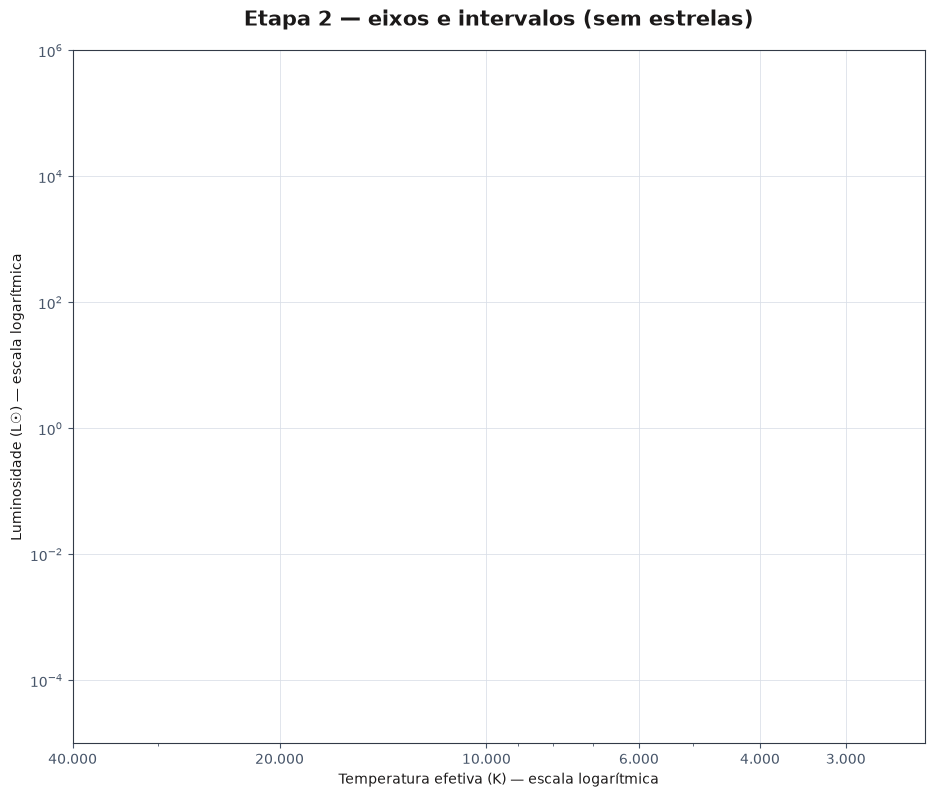

In [8]:
def criar_eixos(titulo="Diagrama Hertzsprung–Russell"):
    fig, ax = plt.subplots(figsize=(11, 9))
    # fig.patch.set_facecolor("#FFFFFF")
    # ax.set_facecolor("#FFFFFF")

    ax.grid(True, which="major", color="#D9DEE7", linewidth=0.7, alpha=0.8)
    ax.tick_params(colors="#475569", which="both")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(T_MAX, T_MIN)   # invertido
    ax.set_ylim(L_MIN, L_MAX)

    # Rótulos legíveis no eixo x (escala log não mostra números "redondos" sozinha)
    marcas = [40000, 20000, 10000, 6000, 4000, 3000]
    ax.xaxis.set_major_locator(FixedLocator(marcas))
    ax.xaxis.set_major_formatter(FixedFormatter([f"{m:,}".replace(",", ".") for m in marcas]))
    ax.xaxis.set_minor_formatter(NullFormatter())

    ax.set_xlabel("Temperatura efetiva (K) — escala logarítmica", color="#1b1919")
    ax.set_ylabel("Luminosidade (L☉) — escala logarítmica", color="#1b1919")
    ax.set_title(titulo, color="#1b1919", fontsize=15, fontweight="bold", pad=18)
    for spine in ax.spines.values():
        spine.set_color("#323A47")
    return fig, ax

fig, ax = criar_eixos("Etapa 2 — eixos e intervalos (sem estrelas)")
plt.show()

## Etapa 3 — Amostra aleatória de 100 estrelas, sem formatação

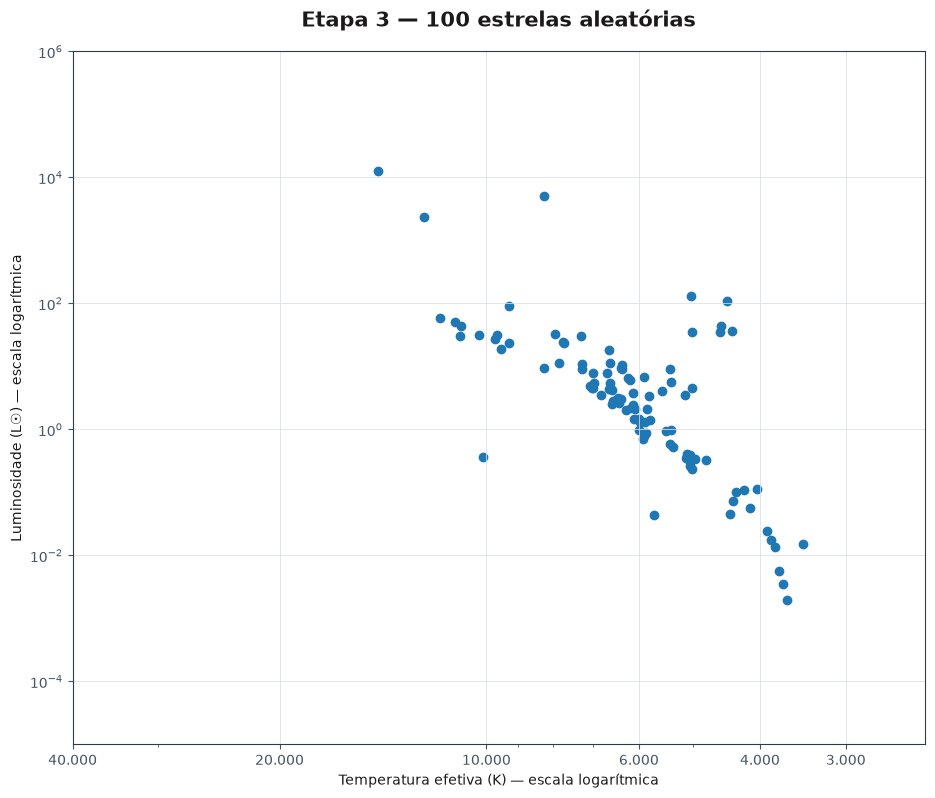

In [9]:
amostra = df.sample(n=100, random_state=42)

fig, ax = criar_eixos("Etapa 3 — 100 estrelas aleatórias")
ax.scatter(amostra["teff"], amostra["lum"])
plt.show()

## Etapa 4 — Adicionando o Sol

O banco tem um registro dedicado:
`Sol,5772.0,1.0,4.83,Sol,Sol — referência,...`

In [10]:
sol = df[df["nome"] == "Sol"]
sol

,HIP,nome,teff,lum,magnitude_absoluta,classe,fonte,Vmag,Plx,e_Plx,B-V
20817,NaN,Sol,5772.0,1.0,4.83,Sol,Sol — referência,NaN,NaN,NaN,NaN


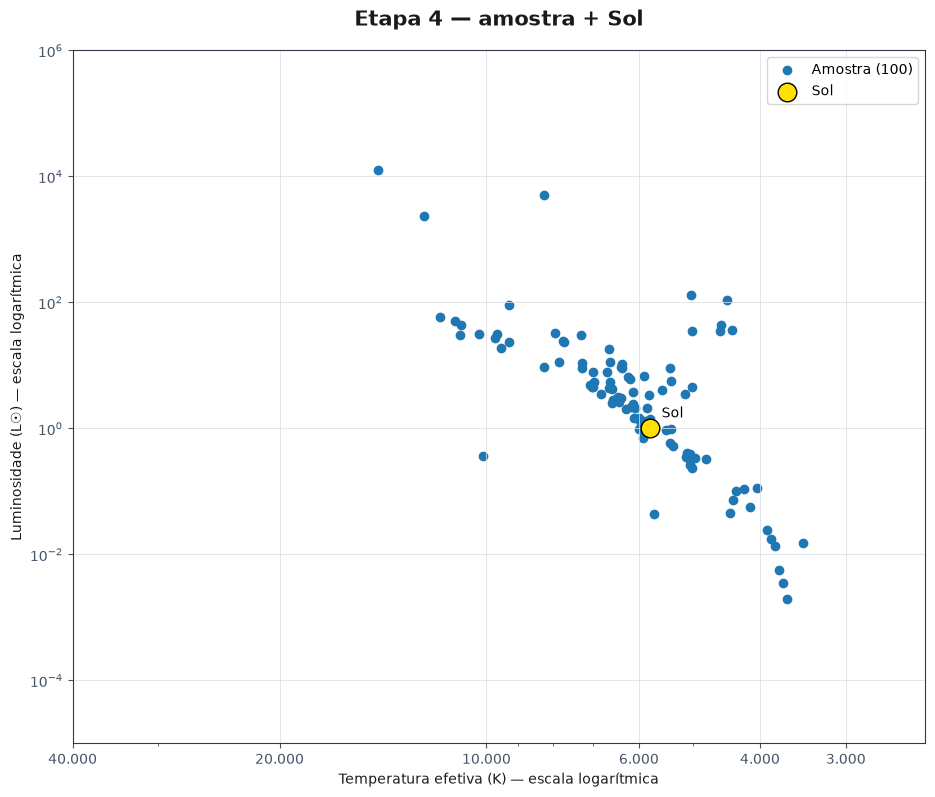

In [11]:
fig, ax = criar_eixos("Etapa 4 — amostra + Sol")
ax.scatter(amostra["teff"], amostra["lum"], label="Amostra (100)")
ax.scatter(sol["teff"], sol["lum"], s=180, c="#ffe000", edgecolors="black", zorder=5, label="Sol")
ax.annotate("Sol", (sol["teff"].iloc[0], sol["lum"].iloc[0]), xytext=(8, 8), textcoords="offset points")
ax.legend()
plt.show()

## Etapa 5 — Explorando as classes

Cada classe recebe uma cor, ainda sem os marcadores e tamanhos finais.

In [12]:
print(df["classe"].value_counts(dropna=False))
print()
print(df.groupby(["classe", "fonte"]).size())

classe
Sequência principal          17710
Gigante                       2544
Anã de baixa luminosidade      560
Anã branca                       5
Supergigante                     4
Sol                              1
Name: count, dtype: int64

classe                     fonte                
Anã branca                 Hipparcos                    1
                           Literatura                   4
Anã de baixa luminosidade  Hipparcos                  560
Gigante                    Hipparcos                 2541
                           Literatura                   3
Sequência principal        Hipparcos                17697
                           Referência aproximada       13
Sol                        Sol — referência             1
Supergigante               Literatura                   4
dtype: int64


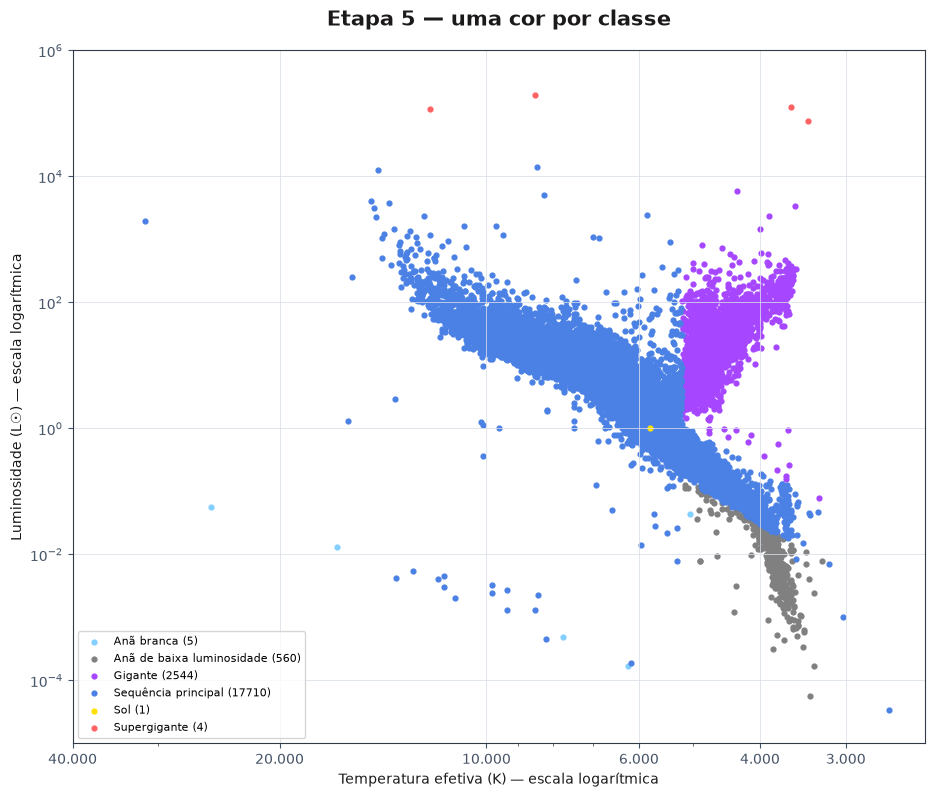

In [13]:
CORES = {
    "Anã branca": "#83cfff",
    "Gigante": "#a647ff",
    "Supergigante": "#ff6262",
    "Sequência principal": "#4b81e4",
    "Sol": "#ffe000",
}

fig, ax = criar_eixos("Etapa 5 — uma cor por classe")
for classe, grupo in df.groupby("classe"):
    ax.scatter(grupo["teff"], grupo["lum"], s=12, color=CORES.get(classe, "gray"), label=f"{classe} ({len(grupo)})")
ax.legend(loc="lower left", fontsize=8)
plt.show()

## Etapa 6 — Classes com o estilo do código original

Pontos **Hipparcos** são observações (pequenos); as **referências** são símbolos maiores, com borda branca.

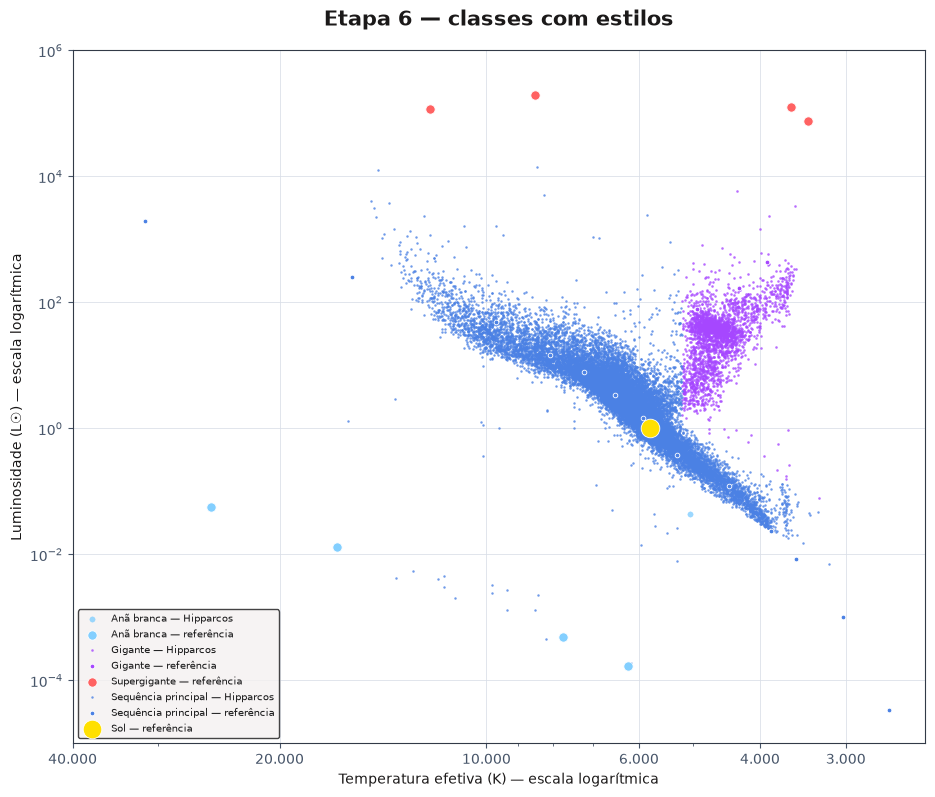

In [14]:
ESTILOS = {  # classe: (cor, marcador, tamanho)
    "Anã branca": ("#83cfff", "o", 15),
    "Gigante": ("#a647ff", ".", 9),
    "Supergigante": ("#ff6262", "o", 10),
    "Sequência principal": ("#4b81e4", ".", 8),
    "Sol": ("#ffe000", "o", 180),
}

NOMES_ROTULADOS = {
    "Sol", "Sirius B", "Rigel", "Deneb", "Betelgeuse", "Antares",
    "Aldebaran", "Arcturus", "Capella", "Procyon B", "40 Eridani B", "van Maanen 2",
}

def plotar_classes(ax, df, rotulos=False):
    for classe, (cor, marcador, tamanho) in ESTILOS.items():
        grupo = df[df["classe"] == classe]
        hip = grupo[grupo["fonte"] == "Hipparcos"]
        ref = grupo[grupo["fonte"] != "Hipparcos"]

        if not hip.empty:
            ax.scatter(hip["teff"], hip["lum"], s=tamanho, c=cor, marker=marcador,
                       alpha=0.8, linewidths=0.25, rasterized=True,
                       label=f"{classe} — Hipparcos", zorder=2)
        if not ref.empty:
            ax.scatter(ref["teff"], ref["lum"], s=max(tamanho, 45), c=cor, marker=marcador,
                       edgecolors="white", linewidths=0.6,
                       label=f"{classe} — referência", zorder=5)
            if rotulos:
                for _, estrela in ref.iterrows():
                    if estrela["nome"] in NOMES_ROTULADOS:
                        ax.annotate(estrela["nome"], (estrela["teff"], estrela["lum"]),
                                    xytext=(5, 5), textcoords="offset points",
                                    color="black", fontsize=8)

fig, ax = criar_eixos("Etapa 6 — classes com estilos")
plotar_classes(ax, df)
ax.legend(loc="lower left", fontsize=7.5, facecolor="#F4F1F1", edgecolor="#161617", labelcolor="#161617")
plt.show()

## Etapa 7 — Raios constantes, rótulos das estrelas e lista de raios

Lei de Stefan–Boltzmann em unidades solares: `L = R² · (T/T☉)⁴`, logo `R = √L / (T/T☉)²`.

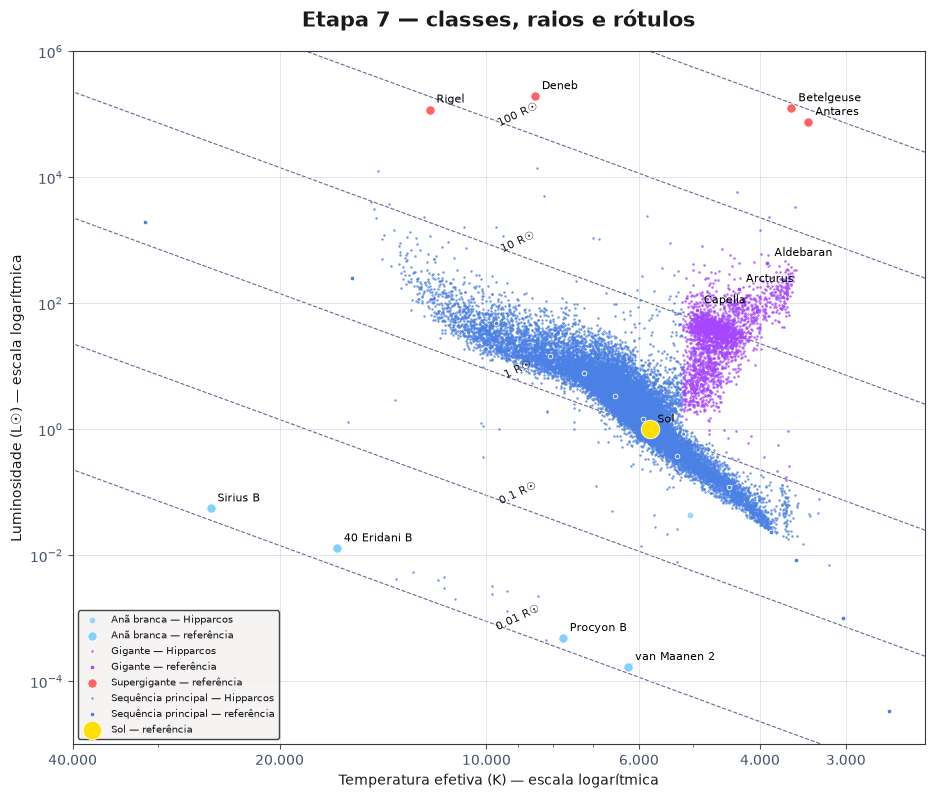

In [15]:
RAIOS = [0.01, 0.1, 1, 10, 100, 1000]

def plotar_raios(ax):
    temperaturas = [T_MIN, T_MAX]
    for raio in RAIOS:
        lums = [raio**2 * (t / T_SOL) ** 4 for t in temperaturas]
        ax.plot(temperaturas, lums, linestyle="--", color="#201555",
                linewidth=0.8, alpha=0.65, zorder=1)
        t_rot = 9000
        l_rot = raio**2 * (t_rot / T_SOL) ** 4
        if L_MIN < l_rot < L_MAX:
            ax.text(t_rot, l_rot, f"{raio:g} R☉", color="#1b1919",
                    fontsize=8, rotation=25, ha="center", va="bottom")

fig, ax = criar_eixos("Etapa 7 — classes, raios e rótulos")
plotar_raios(ax)
plotar_classes(ax, df, rotulos=True)
ax.legend(loc="lower left", fontsize=7.5, facecolor="#F4F1F1", edgecolor="#161617", labelcolor="#161617")
plt.show()

In [16]:
# Lista com os raios das estrelas de referência (não-Hipparcos)
df["raio"] = np.sqrt(df["lum"]) / (df["teff"] / T_SOL) ** 2

referencias = (
    df[df["fonte"] != "Hipparcos"]
    .loc[:, ["nome", "classe", "teff", "lum", "raio"]]
    .sort_values("raio", ascending=False)
)
print(referencias.to_string(index=False, formatters={
    "teff": "{:,.0f}".format, "lum": "{:.3g}".format, "raio": "{:.4g} R☉".format}))

        nome              classe   teff      lum       raio
  Betelgeuse        Supergigante  3,600 1.26e+05   912.5 R☉
     Antares        Supergigante  3,400  7.6e+04   794.5 R☉
       Deneb        Supergigante  8,500 1.96e+05   204.1 R☉
       Rigel        Supergigante 12,100  1.2e+05   78.83 R☉
   Aldebaran             Gigante  3,900      440   45.95 R☉
    Arcturus             Gigante  4,290      170    23.6 R☉
     Capella             Gigante  4,940       78   12.06 R☉
         A0V Sequência principal  9,700     49.2   2.484 R☉
         B5V Sequência principal 15,700      258   2.172 R☉
         A5V Sequência principal  8,080     14.9   1.967 R☉
         F0V Sequência principal  7,220      7.8   1.785 R☉
         B0V Sequência principal 31,400 1.96e+03   1.496 R☉
         F5V Sequência principal  6,510      3.4    1.45 R☉
         G0V Sequência principal  5,920     1.49   1.159 R☉
         Sol                 Sol  5,772        1       1 R☉
         K0V Sequência principal  5,280 

In [ ]:
# Resumo dos raios por classe (todas as estrelas)
df.groupby("classe")["raio"].describe()[["count", "min", "50%", "max"]]

## Etapa 8 — Gradiente de fundo e gráfico final

O gradiente reflete a cor aparente da estrela (azul = quente, vermelho = fria) com opacidade baixa.

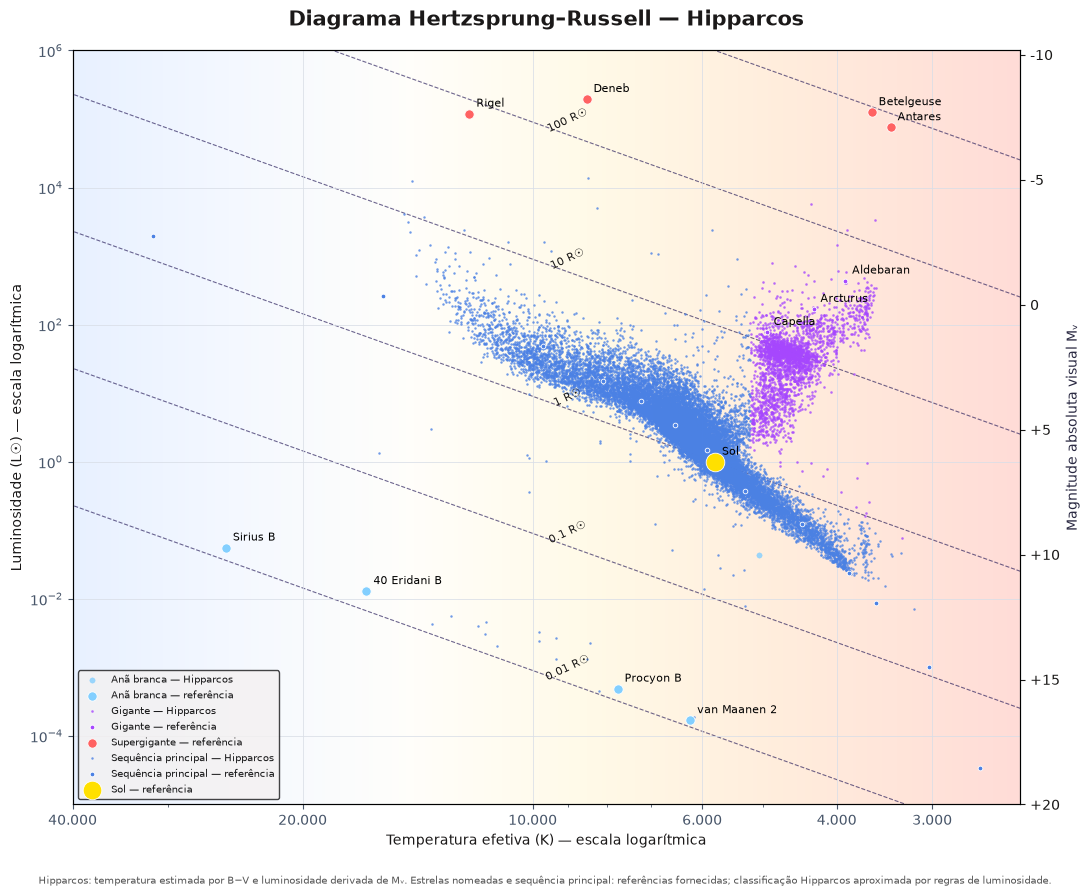

Gráfico salvo em diagrama_hr.png


In [17]:
def plotar_gradiente(ax):
    gradiente = LinearSegmentedColormap.from_list("estrela", [
        (0.00, "#7fb0ff"), (0.18, "#c8dcff"), (0.35, "#fffbe8"),
        (0.55, "#ffe27a"), (0.75, "#ff9a3c"), (1.00, "#ff3b1f"),
    ])
    ax.imshow([list(range(256))], cmap=gradiente, extent=(0, 1, 0, 1),
              transform=ax.transAxes, aspect="auto",
              alpha=OPACIDADE_GRADIENTE, interpolation="bilinear", zorder=0)
    # imshow pode redefinir os limites; reaplica
    ax.set_xlim(T_MAX, T_MIN)
    ax.set_ylim(L_MIN, L_MAX)

fig, ax = criar_eixos("Diagrama Hertzsprung–Russell — Hipparcos")
plotar_gradiente(ax)
plotar_raios(ax)
plotar_classes(ax, df, rotulos=True)
ax.legend(loc="lower left", fontsize=7.5, facecolor="#F4F1F1", edgecolor="#161617", labelcolor="#161617")

# Eixo direito: magnitude absoluta visual
ax_dir = ax.twinx()
ax_dir.set_yscale("log")
ax_dir.set_ylim(ax.get_ylim())
mags = [-10, -5, 0, 5, 10, 15, 20]
ax_dir.set_yticks([10 ** ((4.83 - m) / 2.5) for m in mags])
ax_dir.set_yticklabels([f"{m:+d}" if m else "0" for m in mags])
ax_dir.yaxis.set_minor_formatter(NullFormatter())
ax_dir.set_ylabel("Magnitude absoluta visual Mᵥ", color="#2a2942")
ax_dir.tick_params(axis="y", colors="#191817")

fig.text(0.5, 0.012,
         "Hipparcos: temperatura estimada por B−V e luminosidade derivada de Mᵥ. "
         "Estrelas nomeadas e sequência principal: referências fornecidas; "
         "classificação Hipparcos aproximada por regras de luminosidade.",
         ha="center", color="#555555", fontsize=7)

fig.tight_layout(rect=(0, 0.035, 1, 1))
fig.savefig("diagrama_hr.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()
print("Gráfico salvo em diagrama_hr.png")